# Hälsostudie - Statistisk dataanalys

## 1. Introduktion

I projekten kommer analyseras data från en hälsostudie med hjälp av Python. 

Undersöka deltagarnas hälsodata genom statistik , visualisering, simuleringar och hypetesprövning. 

## 2. Data Loading och Exploration

### 2.1 Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

### 2.2 Load Dataset

In [2]:
df = pd.read_csv("../data/health_study_dataset.csv")

In [3]:
df.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


### 2.3 Initial Exploration

In [4]:
print("Rader och kolumner:",df.shape)

Rader och kolumner: (800, 9)


In [5]:
print("Kolumnnamn:", df.columns)

Kolumnnamn: Index(['id', 'age', 'sex', 'height', 'weight', 'systolic_bp', 'cholesterol',
       'smoker', 'disease'],
      dtype='str')


In [6]:
print("Sista raderna:")
df.tail()

Sista raderna:


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
795,796,65,M,177.2,73.6,174.3,4.31,Yes,0
796,797,49,M,177.4,86.1,150.6,5.40,No,0
797,798,60,F,175.0,49.7,146.5,5.57,No,0
798,799,50,F,172.6,55.3,155.0,3.58,No,0
799,800,50,M,189.2,79.4,139.7,5.62,No,0


In [7]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


### 2.4 Data Quality

In [8]:
print("Missing Values")
df.isnull().sum()

Missing Values


id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

In [9]:
print("Duplicated Rows:")
df.duplicated().sum()

Duplicated Rows:


np.int64(0)

In [10]:
df["id"].duplicated().sum()

np.int64(0)

In [11]:
df["sex"].value_counts(dropna=False)

sex
F    403
M    397
Name: count, dtype: int64

In [12]:
df["smoker"].value_counts(dropna=False)

smoker
No     587
Yes    213
Name: count, dtype: int64

In [13]:
print("Validering av numeriska värden:")

numeric_cols = [
    "age",
    "height",
    "weight",
    "systolic_bp",
    "cholesterol"
]
df[numeric_cols].agg(["min", "max"])

Validering av numeriska värden:


,age,height,weight,systolic_bp,cholesterol
min,18,144.4,33.7,106.8,2.50
max,90,200.4,114.4,185.9,7.88


In [14]:
print("Imposibles värden:")

positive_cols = [
    "height",
    "weight",
    "systolic_bp",
    "cholesterol"
]

(df[positive_cols] <= 0).sum()

Imposibles värden:


height         0
weight         0
systolic_bp    0
cholesterol    0
dtype: int64

In [15]:
df["disease"].value_counts(dropna=False)
# 0 -> med disease
# 1 -> utan det

disease
0    753
1     47
Name: count, dtype: int64

## Data Quality

Dataset innehåller 800 values och 9 variabler. Inga saknade värden eller duplicerade rader eller duplicerade ID upptäcktes. 

De kategoriska variablerna innehåller endast de förväntade värdena, och de numeriska variablerna har rimliga värdeintervall. Inga ogiltiga nollvärden eller negativa värden hittades i de kontrollerande hälsomåtten. 

Variabeln disease innehåller endast värderna 0 och 1.

Utifrån dessa kontroller bedöms datasetet vara lämpligt för fortsatt statistiks analys utan någon omdelbar dataresning. 


### 2.5 Initial Findings 

Den inledande undersökningen visar att datasetet har en tydlig struktur med både numeriska och katergoriska variabler. 

Datakvalitetskontrollerna visade inga uppenbara problem med saknade värden, dubbletter eller ogiltiga kategorier.

Nästa steg är att använda beskrivande statistik och visualiseringgar för att undersöka hur deltagarnas hälsovärden är fördelade.

## 3. Descriptive Statistics

### 3.1 Numerical Variables

In [16]:
descriptive_stats = df[numeric_cols].agg(
    ["mean", "median", "min", "max"]
)

descriptive_stats.round(2)

,age,height,weight,systolic_bp,cholesterol
mean,49.43,171.85,73.41,149.18,4.93
median,50.00,171.35,73.20,149.40,4.97
min,18.00,144.40,33.70,106.80,2.50
max,90.00,200.40,114.40,185.90,7.88


### 3.2 Interpretation of Data

Det kan man se i resultatet of data är att medelålder är 49 år och att medianålder är 50. Medelvikten är 73,41 kg och medellängden är 171,85 cm.

Det genomsnittliga systolika blodtycket är 149,18, medan medelvärdet för kolesterol är 4,93. 

Medelvärdet och medianen ligger nära varandra. Detta visar att de två centralmåtten ger liknande resultat, men det räcker inte för att avgöra hur fördelningarna ser ut. 

### 3.3 Data visualization

#### 3.3.1 Histogram - Systolic Blood Pressure

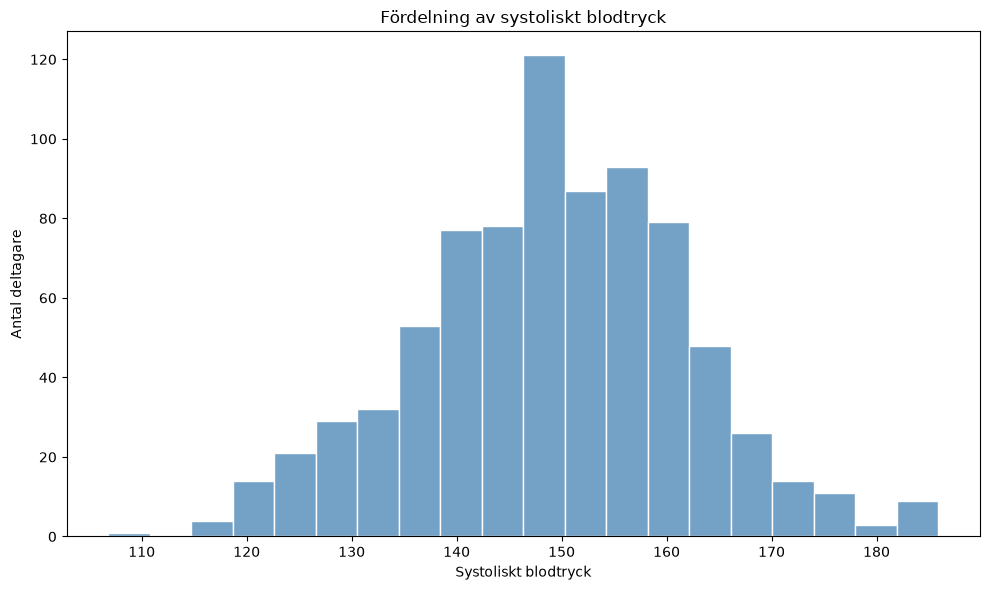

In [17]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=df,
    x="systolic_bp",
    bins=20,
    color="steelblue",
    edgecolor="white"
)

plt.title("Fördelning av systoliskt blodtryck")
plt.xlabel("Systoliskt blodtryck")
plt.ylabel("Antal deltagare")

plt.tight_layout()
plt.show()

#### Tolking av histogrammet

Histogrammet visar att majoritet av deltagarna ligger cirka mellan 135 och 165. 

Fördelningen är ungefär klockformad och relativt symmetrisk, med flest observationer omkring 145-150.

Medelvärdet(149,18) och medianen(149,40) ligger nära varandra, vilket stämmer med histogrammet form.

Det finns få observationer med mycket lägre eller högre blodtryckt.

#### 3.3.2 Boxplot - Weight by Gender

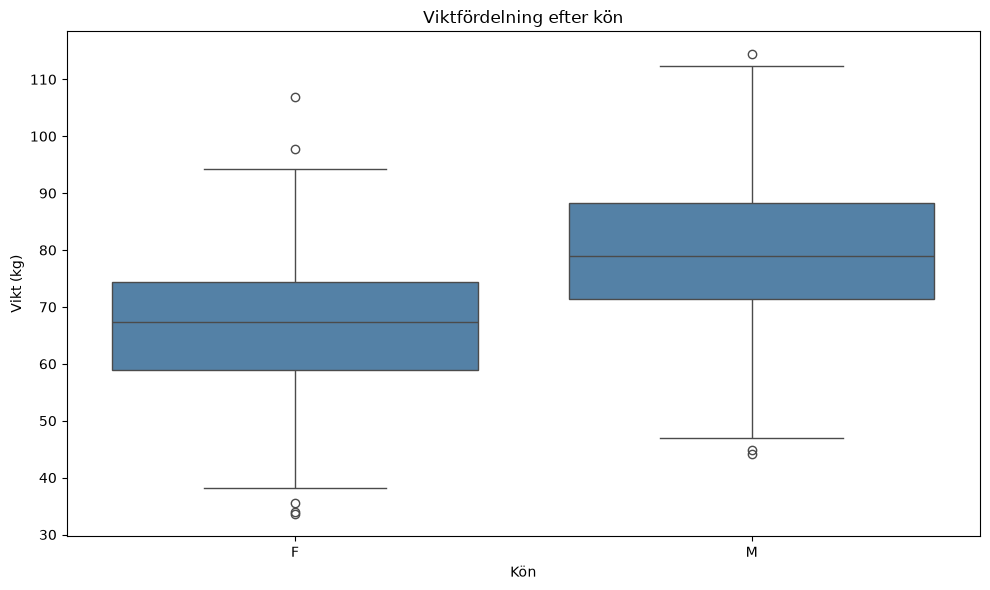

In [18]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="sex",
    y="weight",
    color="steelblue"
)

plt.title("Viktfördelning efter kön")
plt.xlabel("Kön")
plt.ylabel("Vikt (kg)")

plt.tight_layout()
plt.show()

#### Tolking av boxplot

Boxploten visar att män generellt har högre vikt än kvinnor i datasetet.

Medianvikten är ungefär 79 kg för man och 67 kg för kvinnor. Spridningen inom de mittersta 50% av observationerna är något större bland männen.

Båda grupperna innehåller några outliers, både låga och höga.

Diagrammet visar skillnader i viktfördelningen mellan grupperna, men säger inte om skillnaderna är relevanta.

#### 3.3.3 Bar Chart - Smoking Distribution

In [19]:
smoker_pct = df["smoker"].value_counts(normalize=True) * 100

smoker_pct

smoker
No     73.375
Yes    26.625
Name: proportion, dtype: float64

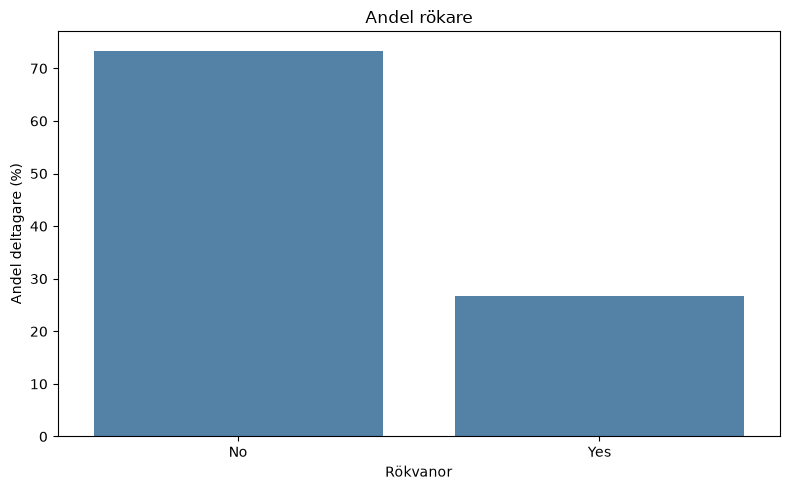

In [20]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=smoker_pct.index,
    y=smoker_pct.values,
    color="steelblue"
)

plt.title("Andel rökare")
plt.xlabel("Rökvanor")
plt.ylabel("Andel deltagare (%)")

plt.tight_layout()
plt.show()

#### Tolkning av stapeldiagrammet 

Diagrammet visar att majoriteten av deltagare i hälsostudien inte röker. 

Av 800 deltagare är 587 personer (73,38%) icke-rökare och 213 personer (26,63 %) rökare.

Andelen icke-rökare är alltså betydligt större än andelen rökare.

Diagrammet visar fördelningen av rökvanor, men säger ingenting om sambandet  mellan rökning och blodtryckt.

## 4. Disease Simulation

### 4.1 Actual Disease Proportion

Först bhöver vi veta sannolikhet att en deltagare har diseases. I data set vi ser att:
- 0 -> utan 
- 1 -> med

För att räkna sannolikhet:

-   P(disease) = Deltagare med disease / Totalt deltagare



In [21]:
disease_count = (df["disease"] == 1).sum()
total_deltagare = len(df)

disease_probability = disease_count / total_deltagare

print("Deltagare med disease:", disease_count)
print("Totalt deltagare:", total_deltagare)
print("Disase sannolikhet:", disease_probability)
print("Disease percent:", round(disease_probability * 100, 2), "%")

Deltagare med disease: 47
Totalt deltagare: 800
Disase sannolikhet: 0.05875
Disease percent: 5.88 %


### 4.2 Random Simulation

Jag kommer att göra en simaltion med två möjliga resultat:

- 0 -> deltagare utan disease
- 1 -> deltagare utan disease

**Saknnolihet : 5,88%** -> simulation med 1.000 personer

In [22]:
# Skapa a random number generator with a fixed seed
rng = np.random.default_rng(seed=42)

#Simulate 1.000 people
simulated_disease = rng.binomial(
    n=1,
    p=disease_probability,
    size=1000
)


In [23]:
simulated_disease_count = simulated_disease.sum()

simulated_disease_proportion = simulated_disease.mean()

print("Simulated deltagare:", len(simulated_disease))
print("Deltagare med disease:", simulated_disease_count)
print("Simulated disease proportion:", simulated_disease_proportion)
print("Simulated disease percentage:", round(simulated_disease_proportion * 100, 2), "%")

Simulated deltagare: 1000
Deltagare med disease: 54
Simulated disease proportion: 0.054
Simulated disease percentage: 5.4 %


### 4.3 Jämföra Resultatet

In [24]:
difference = simulated_disease_proportion - disease_probability

print(f"Aktuellt disease percentange: {disease_probability:.2%}")
print(f"Simulated disease percentage: {simulated_disease_proportion:.2%}")
print(f"Skillnaden: {difference * 100:.3f} percentage ")

Aktuellt disease percentange: 5.88%
Simulated disease percentage: 5.40%
Skillnaden: -0.475 percentage 


#### Tolking 

I dataset har 47 av 800 deltagare sjukdomen, vilket motsvrara 5,88%.

Vid simulering av 1.000 personer med samma sannolikhet fick 54 personer sjukdomen, vilket motsvarar 5,4%.

Skillnaden är 0,475 procentenheter och detta beror på **slumpmässig variation**. Varje simulerad person har 5,875% sannolikhet att få sjukdomen, men det betyder inte att resultatet i hela simulationen kommer att vara exakt 5,875%.

Vi använder en seed så vi kan få samma resultat i koden, men om vi anvönder andra seed resultetat kan variera. 

Simuleringen visar att vi kan få liknande, men inte exakt samma, resultatet även när vi använder samma sannolikhet. 


## 5. Confidence Intervals

### 5.1 Normal Approximation

Man använder **normalapproximation** för att beräkna att 95% konfidensintervall för medelvärdet av det systoliska blodtrycket.

Syftet är att uppskatta inom vilket intervall populationes genomsnittliga står, för att medelvärdet i dataset bara är en uppskattning baserad på ett urval. 

För att bräkna intervallet man använder medelvärdet, standardavvikelsen och antalet observationer. Med dessa beräknar vi felmarginalen.

Eftersom ddaatset har 800 observationer använder man normalaapproximation för att uppskatta osäkrheten kring medelvärdet. 

In [25]:
bp = df["systolic_bp"]

mean_bp = bp.mean()
std_bp = bp.std(ddof=1)
n = bp.count()

standard_error = std_bp / np.sqrt(n)

print("Mean:", round(mean_bp, 2))
print("Standar deviation:", round(std_bp, 2))
print("Sample size:", n)
print("Standard error:", round(standard_error, 4))

Mean: 149.18
Standar deviation: 12.79
Sample size: 800
Standard error: 0.4523


In [27]:
confidence_level = 0.95

z = stats.norm.ppf(1 - (1 - confidence_level) / 2)

margin_error = z * standard_error

ci_lower = mean_bp - margin_error
ci_upper = mean_bp + margin_error

print(f"Konfidensintervall nivå: {confidence_level:.0%}")
print(f"Lower bound: {ci_lower:.2f}")
print(f"Upper bound: {ci_upper:.2f}")

Konfidensintervall nivå: 95%
Lower bound: 148.29
Upper bound: 150.07


#### Tolkning av konfidensintervallet

Medelrvärdet för det systoliska blodtrycket är 149,18. Med hjälp av normalapproximation beräknades ett 95% konfidensintervall mellan **148,29 och 150,07**

Intervallet är relativt smalt **+- 0,89**, vilket tyder på att vi har en ganska precis uppskattning av populationens medelvärdet. 

Ett 95% **konfidensintervall** innebär att om vi upprepade udenrsöokning många gånger och beräkna ett nytt intervall varje gång, skulle ungefär 95% av dessa intercall innehålla verkliga medelvärde.

### 5.2 Bootstrap Method

Methoden innebär att vi upprepade gånger skapar nya stickprov från dataset genom slumpmässigt urval. För varje stickprov beräknas ett nytt medelvärdet. 

Genom dess kan man uppskatta ett konfidensintervall utan att använda normalapproximationes formel. 

In [ ]:
# Bootstrap configuration
rng_boot = np.random.default_rng(seed=42)
n_bootstrap = 5000

bp_values = df["systolic_bp"].to_numpy()
bootstrap_means = []

# Generate bootstrap samples
for i in range(n_bootstrap):
    sample = rng_boot.choice(
        bp_values,
        size=len(bp_values),
        replace=True
    )
    bootstrap_means.append(sample.mean())

bootstrap_means = np.array(bootstrap_means)


In [ ]:
# Räkna med 95% bootstrap

bootstrap_lower = np.percentile(bootstrap_means, 2.5)
bootstrap_upper = np.percentile(bootstrap_means, 97.5)

print(f"Bootstrap samples: {n_bootstrap}")
print(f"Bootstrap mean: {bootstrap_means.mean():.2f}")
print(f"Lower bound: {bootstrap_lower:.2f}")
print(f"Upper bound: {bootstrap_upper:.2f}")

Bootstrap samples: 5000
Bootstrap mean: 149.19
Lower bound: 148.30
Upper bound: 150.06


In [36]:
ci_comparison = pd.DataFrame({
    "Method": ["Normal Approximation", "Bootstrap"],
    "Lower Bound": [ci_lower, bootstrap_lower],
    "Upper Bound": [ci_upper, bootstrap_upper]
})

ci_comparison["Interval Width"] = (
    ci_comparison["Upper Bound"] - ci_comparison["Lower Bound"]
)

ci_comparison.round(2)

,Method,Lower Bound,Upper Bound,Interval Width
0,Normal Approximation,148.29,150.07,1.77
1,Bootstrap,148.30,150.06,1.76


#### Jämförelse och metodval

Båda metoderna gav nästan identiska 95% konfidensintervall för det systoliska blodtrycket.

-   **Nomralapproximation:** 148,29 - 150,07
-   **Bootstrap:** 148,30 - 150,06
  
**Normalapproximation** valden eftersom vi har ett relativ stort stickprov med 800 values. Metoden anvönder standarfelet och normalfördelningen för att beräkna konfidensintervallet.

**Bootstrap** valdes som en alternativ metod eftersom den använder upprepade slumpmässiga urval för att uppskatta osäkerheten kring medelvärdet. 

Resultat visar att båda metoderna ger mycket liknande uppskattningar i detta dataset. De små skillnaderna kan bland annat bero på slumpmässig variation i bootstrap simuleringen.

Båda metoderna förutsätter att observationerna ger ett lämpligt underlag för statisk inferens. Resultates kan inte garanterar att urvalet representativt för hela populationen. 

## 6. Hypothesis Testing 

### 6.1 Hypothesis Formulation

Hypotes är att undersöka om rökare har ett högre systolisk blodtryck än icke-rökare.

- **Nollhypets** -> Rökare har inte högre genomsnittligt systoliskt blodtryck än icke-rökare.
- **Alternativhypotes** -> Rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare.

### 6.2 Group comparison

In [37]:
smokers_bp = df.loc[df["smoker"] == "Yes", "systolic_bp"]
non_smokers_bp = df.loc[df["smoker"] == "No", "systolic_bp"]

In [38]:
print("Smokers:")
print("Deltagare:", len(smokers_bp))
print("Mean BP:", round(smokers_bp.mean(), 2))
print("Standard deviation:", round(smokers_bp.std(), 2))

print("\nNon-smokers:")
print("Delatagare:", len(non_smokers_bp))
print("Mean BP:", round(non_smokers_bp.mean(), 2))
print("Standard deviation:", round(non_smokers_bp.std(), 2))

Smokers:
Deltagare: 213
Mean BP: 149.52
Standard deviation: 13.27

Non-smokers:
Delatagare: 587
Mean BP: 149.05
Standard deviation: 12.63


#### Tolking av gruppjämförelsen

Rökarna har genomsnittligt systoliskt blodtryck på 149,52, medan icke-rökarna har 149,05.

Skillnaden mellan gruppernas medelvärden är endast **0,47**. Standardavvikelsen är betydligt större än denna skillnad i båda grupperna.

Rökarna har alltså ett något högre medelvärde i dataset.

### 6.3 Statistical test / t-test

Kommer använda **t-test** för att undersöka om rökare har högre genomsnittligt systoliskt än icke-rökare.

Med metoden kommer att jamföra medelväden mellan två oberoende grupper. T-test kräver inte att grupperna har samma varians. vilket göt metoden lämplog även när gruppernas storlek och spridning skiljer sig åt.

Om p-värdet är mindra än 0,05 förkastat vi nollhypotesen.

In [39]:
alpha = 0.05

t_stat, p_values = stats.ttest_ind(
    smokers_bp,
    non_smokers_bp,
    equal_var=False,
    alternative="greater"
)

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_values:.4f}")

T-statistic: 0.4503
P-value: 0.3264


### 6.4 Sammanfattning

T-test gav ett **t-värdet på 0,4503** och ett **p-värdet på 0,3264**

Eftersom p-värdet är större än signikansnivån 0,05 man kän brkräfta att rökarna har ett något högre genomsnittligt blodtryckt (149,52) än icke-rökarna (149,05), men skillnaden är **inte statiskt signifikant.**

Resultatet innebär att vi inte har tillräckligt med statistika belägg för att säga att rökare har högre genomsnittligt blodtryck än icke-rökare i den data som finns i dataset.

Det betyder inte att vi har bevisat att det inte finns någon skillnad mellan grupperna.

## 7. Statistical Poer Simulation

### 7.1 Simulation 

Kommer att göras en simuleringen för att undersöka hur ofts t-test kan upptäcka en verklig skillmad i blodtryckt mellan roköare och icke-rökare.

Med ett simulerat scenario där rökarna har 2 högre medelblodtryckt än icke-rökarna. Detta är ett hypotes simulering och inte ett ressultat från dataset.

Kommer använda samma gruppstorlekar och standaravvikelser som i den ursprungliga studein coh antar normarfördelade blodtrycksvärden. 

Genom att upprepa simulering 2 000 gånger och använda signifikansnivån 0,05 kan man uppskatta hur ofta testet upptäcker skillnaden.

In [47]:
# Simulation config
rng_power = np.random.default_rng(seed=42)

n_simuliring = 2000
effect = 2.0

# Original group stats
n_smokers = len(smokers_bp)
n_non_smokers = len(non_smokers_bp)

std_smokers = smokers_bp.std(ddof=1)
std_non_smokers = non_smokers_bp.std(ddof=1)

# Hypothes population means
mean_non_smokers = non_smokers_bp.mean()
mean_smokers = mean_non_smokers + effect


In [48]:
print("Rökare:", n_smokers)
print("Icke-rökare:", n_non_smokers)
print("Assumed mean skillanden:", effect)
print("Simulation:", n_simuliring)

Rökare: 213
Icke-rökare: 587
Assumed mean skillanden: 2.0
Simulation: 2000


### 7.2 Hypthes test simluation

In [50]:
p_values = []

for i in range(n_simuliring):

    # Skapa simulering bloodtryck data
    sim_smokers = rng_power.normal(
        loc=mean_smokers,
        scale=std_smokers,
        size=n_smokers
    )

    sim_non_smokers = rng_power.normal(
        loc=mean_non_smokers,
        scale=std_non_smokers,
        size=n_non_smokers
    )

    # t-test
    result = stats.ttest_ind(
        sim_smokers,
        sim_non_smokers,
        equal_var=False,
        alternative="greater"
    )

    p_values.append(result.pvalue)

p_values = np.array(p_values)

### 7.3 Statistical räkning

In [51]:
# Count statstically results

significant_tests = np.sum(p_values < alpha)

# Uppskatta statisk styrka
statistical_power = significant_tests / n_simuliring

print("Totalt simulations:", n_simuliring)
print("Test:", significant_tests)
print(f"Uppskattad statisk styrka: {statistical_power:.4f}")
print(f"Statiskt styrka percentage: {statistical_power:.2%}")

Totalt simulations: 2000
Test: 1170
Uppskattad statisk styrka: 0.5850
Statiskt styrka percentage: 58.50%


### 7.4 Interpretation 

Simulering genomförder 2 000 ggr med en antagen verklig skillnad på 2 mellan rökare och icke-rökare.

Av dessa simulering gav 1 170 ett statistiks signifikant resultat, vilket motsvarar en uppskattad statistiks styrka på 58,5%.

Det innebär att vårt t-test upptäckte skillnaden i ungefär 59 % av simuleringarna i den simulerande populationerna. 

Resultates visar att test har en begränsad förmåga att upptäcka en skillnad på 2.

Detta är viktig när vi tolkar resultatet från vår tidigare hypothesprvövning. Ett icke signifikant resulat betyder inte automatiskt att det saknas en verklig skillnad mellan grupperna. 

### 7.5 Metod 

Ja valde att använda t-test för att jag ville göra en jamför med 2 oberoende grupper med olika gruppstroleker. Metoden kräver inte att grupperna har samma varians. 

Jag täankte att göra hypotetisk skillnad av 2 för att undersöka hur bra test kunde upptäcka en relativt skillnad i blodtryck.

Genomförde 1 000 simuleringar för att uppskatta test statistika styrka. Använde samma gruppstorlekar och standarvvikelser som i dataset, också en fast seed för att göra simuleringan reproducerbar. 

**Begränsningar:** Simulering bygger på antangadet att blodtrycksvärdena är normalfördelade och att data är oberoende. Resultatet på 59% gäller på den senario och detta kan bli olika om man ändrar till exempel skillnaden i blodtryck eller spridningen. 

##### Källor
- https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html - Dokumentation om t-test

- https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.normal - Dokumentation om simulering med normalfördelade slumpvärden
